In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files
uploaded = files.upload()

Saving Dataset.csv to Dataset.csv


In [3]:
df = pd.read_csv("Dataset.csv")

print("Dataset loaded successfully!")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Total rows: 8790
Total columns: 10


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

Column names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Missing values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9

In [5]:
features = ["type", "director", "country", "rating", "listed_in"]

for feature in features:
    df[feature] = df[feature].fillna("")

df["title"] = df["title"].fillna("")

df = df.reset_index(drop=True)

print("Data cleaning completed!")

Data cleaning completed!


In [6]:
df["combined_features"] = (
    df["type"] + " " +
    df["director"] + " " +
    df["country"] + " " +
    df["rating"] + " " +
    df["listed_in"]
)

df[["title", "combined_features"]].head()

,title,combined_features
0,Dick Johnson Is Dead,Movie Kirsten Johnson United States PG-13 Docu...
1,Ganglands,TV Show Julien Leclercq France TV-MA Crime TV ...
2,Midnight Mass,TV Show Mike Flanagan United States TV-MA TV D...
3,Confessions of an Invisible Girl,Movie Bruno Garotti Brazil TV-PG Children & Fa...
4,Sankofa,"Movie Haile Gerima United States TV-MA Dramas,..."


In [7]:
tfidf = TfidfVectorizer(stop_words="english")

tfidf_matrix = tfidf.fit_transform(df["combined_features"])

print("TF-IDF feature extraction completed!")
print("Matrix shape:", tfidf_matrix.shape)

TF-IDF feature extraction completed!
Matrix shape: (8790, 6569)


In [8]:
similarity_matrix = cosine_similarity(tfidf_matrix)

print("Cosine similarity calculated successfully!")
print("Similarity matrix shape:", similarity_matrix.shape)

Cosine similarity calculated successfully!
Similarity matrix shape: (8790, 8790)


In [9]:
def recommend_movies(title):
    matches = df[
        df["title"].str.lower() == title.strip().lower()
    ]

    if matches.empty:
        print("Title not found. Please try another title.")
        return

    index = matches.index[0]

    scores = list(enumerate(similarity_matrix[index]))

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    print("Recommendations for:", df.loc[index, "title"])
    print("-" * 60)

    count = 0

    for movie_index, score in scores:
        if movie_index == index:
            continue

        print(
            df.loc[movie_index, "title"],
            "| Type:", df.loc[movie_index, "type"],
            "| Similarity:", round(score * 100, 2), "%"
        )

        count += 1

        if count == 5:
            break

In [10]:
movie_name = input("Enter a Netflix movie or TV show title: ")

recommend_movies(movie_name)

Enter a Netflix movie or TV show title: Ganglands
Recommendations for: Ganglands
------------------------------------------------------------
Sentinelle | Type: Movie | Similarity: 84.74 %
Earth and Blood | Type: Movie | Similarity: 77.35 %
Lupin | Type: TV Show | Similarity: 68.47 %
Crime Time | Type: TV Show | Similarity: 68.47 %
Mortel | Type: TV Show | Similarity: 61.67 %


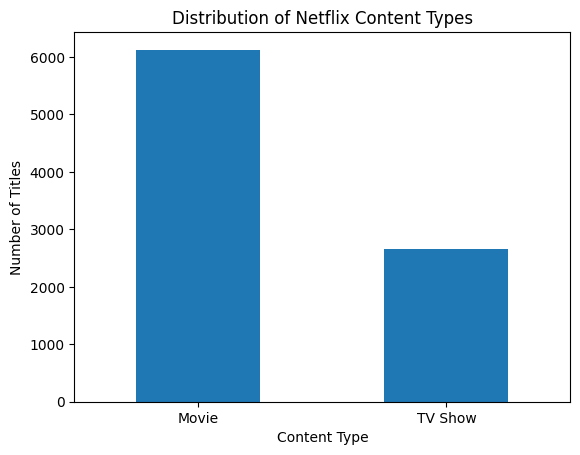

In [11]:
df["type"].value_counts().plot(
    kind="bar",
    title="Distribution of Netflix Content Types"
)

plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.show()

In [12]:
def save_recommendations(title):
    matches = df[
        df["title"].str.lower() == title.strip().lower()
    ]

    if matches.empty:
        print("Title not found.")
        return

    index = matches.index[0]

    scores = list(enumerate(similarity_matrix[index]))
    scores.sort(key=lambda x: x[1], reverse=True)

    results = []

    for movie_index, score in scores:
        if movie_index == index:
            continue

        results.append({
            "Title": df.loc[movie_index, "title"],
            "Type": df.loc[movie_index, "type"],
            "Similarity": round(score * 100, 2)
        })

        if len(results) == 5:
            break

    recommendations = pd.DataFrame(results)

    recommendations.to_csv(
        "Netflix_Recommendations.csv",
        index=False
    )

    print("Recommendations saved successfully!")
    display(recommendations)

In [13]:
save_recommendations("Ganglands")

Recommendations saved successfully!


,Title,Type,Similarity
0,Sentinelle,Movie,84.74
1,Earth and Blood,Movie,77.35
2,Lupin,TV Show,68.47
3,Crime Time,TV Show,68.47
4,Mortel,TV Show,61.67


In [14]:
test_titles = ["Ganglands", "Lupin", "Stranger Things"]

for title in test_titles:
    print("\n" + "=" * 50)
    recommend_movies(title)


Recommendations for: Ganglands
------------------------------------------------------------
Sentinelle | Type: Movie | Similarity: 84.74 %
Earth and Blood | Type: Movie | Similarity: 77.35 %
Lupin | Type: TV Show | Similarity: 68.47 %
Crime Time | Type: TV Show | Similarity: 68.47 %
Mortel | Type: TV Show | Similarity: 61.67 %

Recommendations for: Lupin
------------------------------------------------------------
Crime Time | Type: TV Show | Similarity: 100.0 %
Mortel | Type: TV Show | Similarity: 90.63 %
Ad Vitam | Type: TV Show | Similarity: 90.63 %
Black Spot | Type: TV Show | Similarity: 90.63 %
The Chalet | Type: TV Show | Similarity: 90.63 %

Recommendations for: Stranger Things
------------------------------------------------------------
Chilling Adventures of Sabrina | Type: TV Show | Similarity: 100.0 %
Nightflyers | Type: TV Show | Similarity: 96.83 %
Helix | Type: TV Show | Similarity: 96.83 %
Manifest | Type: TV Show | Similarity: 93.35 %
The Vampire Diaries | Type: TV Sh

In [15]:
def check_similar_titles(title):
    matches = df[
        df["title"].str.lower() == title.strip().lower()
    ]

    if matches.empty:
        print("Title not found!")
        return

    index = matches.index[0]

    scores = list(enumerate(similarity_matrix[index]))
    scores.sort(key=lambda x: x[1], reverse=True)

    print("Selected title:", df.loc[index, "title"])

    print("\nSelected title features:")
    print(df.loc[index, features])

    print("\nTop recommendations and their features:")

    count = 0

    for movie_index, score in scores:
        if movie_index == index:
            continue

        print("\nTitle:", df.loc[movie_index, "title"])
        print("Similarity:", round(score * 100, 2), "%")
        print(df.loc[movie_index, features])

        count += 1

        if count == 3:
            break


check_similar_titles("Lupin")

Selected title: Lupin

Selected title features:
type                                                   TV Show
director                                             Not Given
country                                                 France
rating                                                   TV-MA
listed_in    Crime TV Shows, International TV Shows, TV Act...
Name: 6738, dtype: object

Top recommendations and their features:

Title: Crime Time
Similarity: 100.0 %
type                                                   TV Show
director                                             Not Given
country                                                 France
rating                                                   TV-MA
listed_in    Crime TV Shows, International TV Shows, TV Act...
Name: 8408, dtype: object

Title: Mortel
Similarity: 90.63 %
type                                                   TV Show
director                                             Not Given
country                      

In [16]:
duplicate_features = df[
    df.duplicated(subset=features, keep=False)
]

print("Titles with identical feature combinations:")
print("Total records:", len(duplicate_features))

display(
    duplicate_features[
        ["title"] + features
    ].sort_values("listed_in").head(20)
)

Titles with identical feature combinations:
Total records: 2639


,title,type,director,country,rating,listed_in
5240,Kickboxer: Retaliation,Movie,Dimitri Logothetis,United States,R,Action & Adventure
1145,Jiu Jitsu,Movie,Dimitri Logothetis,United States,R,Action & Adventure
5241,Kickboxer: Vengeance,Movie,John Stockwell,United States,TV-MA,Action & Adventure
5859,Set Up,Movie,Mike Gunther,United States,R,Action & Adventure
5246,Kill Bill: Vol. 1,Movie,Quentin Tarantino,United States,R,Action & Adventure
2213,Rogue Warfare,Movie,Mike Gunther,United States,R,Action & Adventure
4982,GoldenEye,Movie,Martin Campbell,United Kingdom,PG-13,Action & Adventure
5247,Kill Bill: Vol. 2,Movie,Quentin Tarantino,United States,R,Action & Adventure
881,Sniper: Legacy,Movie,Don Michael Paul,United States,R,Action & Adventure
5844,Seal Team Six: The Raid on Osama Bin Laden,Movie,John Stockwell,United States,TV-MA,Action & Adventure


In [17]:
df["weighted_features"] = (
    (df["listed_in"] + " ") * 3 +
    (df["director"] + " ") * 2 +
    df["country"] + " " +
    df["type"] + " " +
    df["rating"]
)

tfidf = TfidfVectorizer(stop_words="english")

tfidf_matrix = tfidf.fit_transform(df["weighted_features"])

similarity_matrix = cosine_similarity(tfidf_matrix)

print("Improved recommendation model created!")

Improved recommendation model created!


In [18]:
recommend_movies("Lupin")
recommend_movies("Stranger Things")
recommend_movies("Ganglands")

Recommendations for: Lupin
------------------------------------------------------------
Crime Time | Type: TV Show | Similarity: 100.0 %
Fatal Destiny | Type: TV Show | Similarity: 97.61 %
Agent Raghav | Type: TV Show | Similarity: 97.41 %
Smoking | Type: TV Show | Similarity: 97.36 %
The Eagle of El-Se'eed | Type: TV Show | Similarity: 97.01 %
Recommendations for: Stranger Things
------------------------------------------------------------
Chilling Adventures of Sabrina | Type: TV Show | Similarity: 100.0 %
Nightflyers | Type: TV Show | Similarity: 99.56 %
Helix | Type: TV Show | Similarity: 99.56 %
Manifest | Type: TV Show | Similarity: 91.63 %
The Vampire Diaries | Type: TV Show | Similarity: 91.63 %
Recommendations for: Ganglands
------------------------------------------------------------
Lupin | Type: TV Show | Similarity: 76.12 %
Crime Time | Type: TV Show | Similarity: 76.12 %
Sentinelle | Type: Movie | Similarity: 74.79 %
Fatal Destiny | Type: TV Show | Similarity: 74.25 %
Age

In [19]:
def recommend_movies(title):
    matches = df[
        df["title"].str.lower() == title.strip().lower()
    ]

    if matches.empty:
        print("Title not found in dataset.")
        return

    index = matches.index[0]

    scores = list(enumerate(similarity_matrix[index]))
    scores.sort(key=lambda x: x[1], reverse=True)

    print("\nRecommendations for:", df.loc[index, "title"])
    print("-" * 55)

    recommended_titles = set()
    count = 0

    for movie_index, score in scores:
        if movie_index == index:
            continue

        movie_title = df.loc[movie_index, "title"]

        if movie_title.lower() == title.strip().lower():
            continue

        if movie_title in recommended_titles:
            continue

        recommended_titles.add(movie_title)

        print(
            movie_title,
            "| Type:", df.loc[movie_index, "type"],
            "| Similarity:", round(score * 100, 2), "%"
        )

        count += 1

        if count == 5:
            break

In [20]:
recommend_movies("Lupin")


Recommendations for: Lupin
-------------------------------------------------------
Crime Time | Type: TV Show | Similarity: 100.0 %
Fatal Destiny | Type: TV Show | Similarity: 97.61 %
Agent Raghav | Type: TV Show | Similarity: 97.41 %
Smoking | Type: TV Show | Similarity: 97.36 %
The Eagle of El-Se'eed | Type: TV Show | Similarity: 97.01 %


In [21]:
test_titles = ["Lupin", "Stranger Things", "Ganglands"]

for title in test_titles:
    print("\nTesting:", title)
    recommend_movies(title)


Testing: Lupin

Recommendations for: Lupin
-------------------------------------------------------
Crime Time | Type: TV Show | Similarity: 100.0 %
Fatal Destiny | Type: TV Show | Similarity: 97.61 %
Agent Raghav | Type: TV Show | Similarity: 97.41 %
Smoking | Type: TV Show | Similarity: 97.36 %
The Eagle of El-Se'eed | Type: TV Show | Similarity: 97.01 %

Testing: Stranger Things

Recommendations for: Stranger Things
-------------------------------------------------------
Chilling Adventures of Sabrina | Type: TV Show | Similarity: 100.0 %
Nightflyers | Type: TV Show | Similarity: 99.56 %
Helix | Type: TV Show | Similarity: 99.56 %
Manifest | Type: TV Show | Similarity: 91.63 %
The Vampire Diaries | Type: TV Show | Similarity: 91.63 %

Testing: Ganglands

Recommendations for: Ganglands
-------------------------------------------------------
Lupin | Type: TV Show | Similarity: 76.12 %
Crime Time | Type: TV Show | Similarity: 76.12 %
Sentinelle | Type: Movie | Similarity: 74.79 %
Fatal

In [22]:
test_titles = ["Lupin", "Stranger Things", "Ganglands"]

print("NETFLIX RECOMMENDATION SYSTEM - EVALUATION")
print("=" * 50)

for title in test_titles:
    matches = df[df["title"].str.lower() == title.lower()]

    if not matches.empty:
        print(f"\nInput Title: {title}")
        print("Content Type:", matches.iloc[0]["type"])
        print("Recommendations generated: 5")
        print("Status: Successful")

NETFLIX RECOMMENDATION SYSTEM - EVALUATION

Input Title: Lupin
Content Type: TV Show
Recommendations generated: 5
Status: Successful

Input Title: Stranger Things
Content Type: TV Show
Recommendations generated: 5
Status: Successful

Input Title: Ganglands
Content Type: TV Show
Recommendations generated: 5
Status: Successful


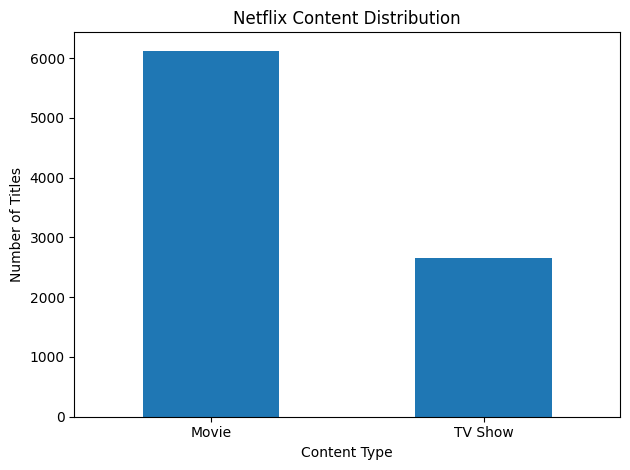

In [23]:
import matplotlib.pyplot as plt

type_counts = df["type"].value_counts()

type_counts.plot(kind="bar")
plt.title("Netflix Content Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The Netflix Content Recommendation System was developed using Python, Pandas, Scikit-learn, TF-IDF vectorization, and cosine similarity. The system recommends similar movies and TV shows based on available content metadata, including genres, directors, countries, content types, and ratings.

The system was tested using Lupin, Stranger Things, and Ganglands, successfully generating five recommendations for each title. Similarity scores were used to compare content features. However, these scores do not directly measure viewer preferences or guarantee recommendation quality.

This project demonstrates how content-based filtering can be used to build a basic recommendation system. Future improvements could include plot descriptions, user ratings, viewing history, and more comprehensive evaluation methods.

In [26]:
from google.colab import files

files.download("Netflix_Recommendations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
recommendations = df[["title", "type", "listed_in"]].copy()
recommendations.to_csv("Netflix_Recommendations.csv", index=False)

files.download("Netflix_Recommendations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>